# Survival Lab

## By: Hannah Dykens, Hannah Sweazey, and Tejas Reddy

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends

    Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.

3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from statsmodels.base.model import GenericLikelihoodModel

1. 

In [91]:
df = pd.read_csv('./data/metabric.csv')

In [92]:
df.head()

,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Chemotherapy,Hormone Therapy,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),Overall Survival Status,Radio Therapy,TMB (nonsynonymous),Tumor Size,Tumor Stage
0,43.19,BREAST CONSERVING,Breast Cancer,NO,YES,0.0,2.0,4.020,84.633333,0:LIVING,YES,2.615035,10.0,1.0
1,48.87,MASTECTOMY,Breast Cancer,YES,YES,1.0,2.0,4.030,163.700000,1:DECEASED,NO,2.615035,15.0,2.0
2,47.68,MASTECTOMY,Breast Cancer,YES,YES,3.0,1.0,4.050,164.933333,0:LIVING,YES,1.307518,25.0,2.0
3,76.97,MASTECTOMY,Breast Cancer,YES,YES,8.0,2.0,6.080,41.366667,1:DECEASED,YES,2.615035,40.0,2.0
4,78.77,MASTECTOMY,Breast Cancer,NO,YES,0.0,4.0,4.062,7.800000,1:DECEASED,YES,5.230071,31.0,4.0


Text(0.5, 1.0, 'PMF of Overall Survival Status')

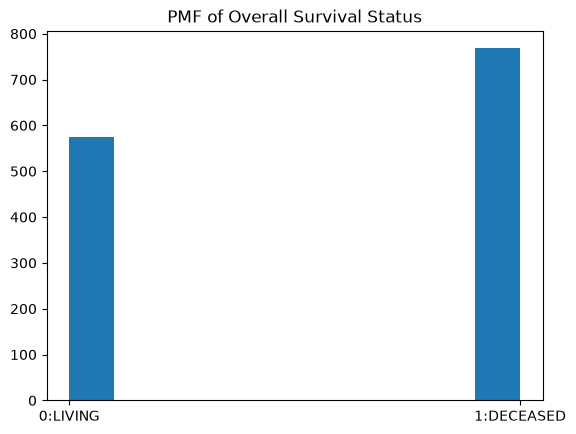

In [93]:
# Tabulates the "Overall Survival Status"
plt.hist(df['Overall Survival Status'])
plt.title("PMF of Overall Survival Status")

In [94]:
df["Tumor Stage"].value_counts()

Tumor Stage
2.0    767
1.0    458
3.0    109
4.0      7
0.0      2
Name: count, dtype: int64

In [95]:
# Dropped the observations where tumor stage is 0.0
df = df.rename({'Tumor Stage': 'TumorStage'}, axis = 1)
df = df.query("TumorStage != 0.0")
df = df.rename({'TumorStage': 'Tumor Stage'}, axis = 1)
df['Tumor Stage'].value_counts()

Tumor Stage
2.0    767
1.0    458
3.0    109
4.0      7
Name: count, dtype: int64

Text(0.5, 1.0, 'Months Survived Hued by Overall Survival')

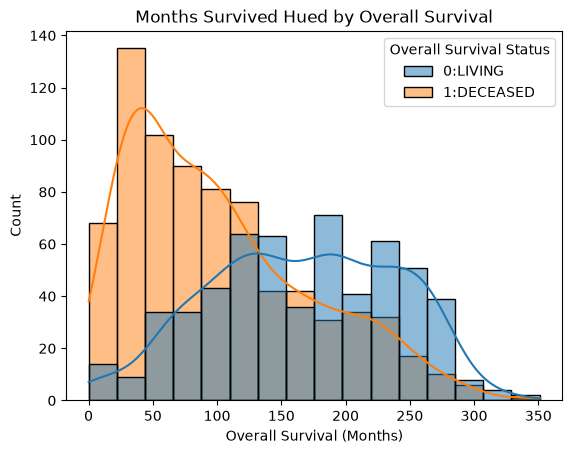

In [96]:
sns.histplot(data=df, x='Overall Survival (Months)', hue='Overall Survival Status', kde=True).set_title('Months Survived Hued by Overall Survival')

2.

## Bad Model 1

In [97]:
# We will not use this as a predictor as it is the same for each entry.
df['Cancer Type'].value_counts()

Cancer Type
Breast Cancer    1341
Name: count, dtype: int64

In [98]:
# Create a DataFrame containing all the columns that we want to use for the first bad prediction.
df_for_regression = pd.get_dummies(df, columns = ['Type of Breast Surgery',  'Chemotherapy', 'Hormone Therapy', 'Radio Therapy', 'Tumor Stage']).drop(columns = ['Cancer Type'])

In [99]:
df_for_regression.columns

Index(['Age at Diagnosis', 'Lymph nodes examined positive', 'Mutation Count',
       'Nottingham prognostic index', 'Overall Survival (Months)',
       'Overall Survival Status', 'TMB (nonsynonymous)', 'Tumor Size',
       'Type of Breast Surgery_BREAST CONSERVING',
       'Type of Breast Surgery_MASTECTOMY', 'Chemotherapy_NO',
       'Chemotherapy_YES', 'Hormone Therapy_NO', 'Hormone Therapy_YES',
       'Radio Therapy_NO', 'Radio Therapy_YES', 'Tumor Stage_1.0',
       'Tumor Stage_2.0', 'Tumor Stage_3.0', 'Tumor Stage_4.0'],
      dtype='object')

In [100]:
# Turn "True" to 1.0 and "False" to 0.0
df_regression_features = ['Age at Diagnosis', 'Lymph nodes examined positive', 'Mutation Count',
       'Nottingham prognostic index', 'TMB (nonsynonymous)', 'Tumor Size',
       'Type of Breast Surgery_BREAST CONSERVING',
       'Type of Breast Surgery_MASTECTOMY', 'Chemotherapy_NO',
       'Chemotherapy_YES', 'Hormone Therapy_NO', 'Hormone Therapy_YES',
       'Radio Therapy_NO', 'Radio Therapy_YES', 'Tumor Stage_1.0',
       'Tumor Stage_2.0', 'Tumor Stage_3.0', 'Tumor Stage_4.0']

df_for_regression[df_regression_features] = df_for_regression[df_regression_features].astype(float)

In [101]:
df_for_regression.dtypes

Age at Diagnosis                            float64
Lymph nodes examined positive               float64
Mutation Count                              float64
Nottingham prognostic index                 float64
Overall Survival (Months)                   float64
Overall Survival Status                      object
TMB (nonsynonymous)                         float64
Tumor Size                                  float64
Type of Breast Surgery_BREAST CONSERVING    float64
Type of Breast Surgery_MASTECTOMY           float64
Chemotherapy_NO                             float64
Chemotherapy_YES                            float64
Hormone Therapy_NO                          float64
Hormone Therapy_YES                         float64
Radio Therapy_NO                            float64
Radio Therapy_YES                           float64
Tumor Stage_1.0                             float64
Tumor Stage_2.0                             float64
Tumor Stage_3.0                             float64
Tumor Stage_

In [102]:
df_for_regression

,Age at Diagnosis,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),Overall Survival Status,TMB (nonsynonymous),Tumor Size,Type of Breast Surgery_BREAST CONSERVING,Type of Breast Surgery_MASTECTOMY,Chemotherapy_NO,Chemotherapy_YES,Hormone Therapy_NO,Hormone Therapy_YES,Radio Therapy_NO,Radio Therapy_YES,Tumor Stage_1.0,Tumor Stage_2.0,Tumor Stage_3.0,Tumor Stage_4.0
0,43.19,0.0,2.0,4.020,84.633333,0:LIVING,2.615035,10.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0
1,48.87,1.0,2.0,4.030,163.700000,1:DECEASED,2.615035,15.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
2,47.68,3.0,1.0,4.050,164.933333,0:LIVING,1.307518,25.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3,76.97,8.0,2.0,6.080,41.366667,1:DECEASED,2.615035,40.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
4,78.77,0.0,4.0,4.062,7.800000,1:DECEASED,5.230071,31.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1338,70.65,0.0,9.0,2.040,201.166667,0:LIVING,11.767659,20.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
1339,75.62,0.0,4.0,4.040,105.200000,1:DECEASED,5.230071,20.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
1340,52.84,6.0,5.0,5.040,200.333333,0:LIVING,6.537589,20.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1341,48.59,1.0,6.0,5.060,14.700000,1:DECEASED,7.845106,30.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


In [103]:
train, test = train_test_split(df_for_regression, test_size = 0.2, random_state = 36)

bad_model_1 = sm.OLS(train['Overall Survival (Months)'], (train[df_regression_features])).fit()
print(bad_model_1.summary())

                                OLS Regression Results                               
Dep. Variable:     Overall Survival (Months)   R-squared:                       0.159
Model:                                   OLS   Adj. R-squared:                  0.149
Method:                        Least Squares   F-statistic:                     15.41
Date:                       Tue, 17 Nov 2026   Prob (F-statistic):           2.10e-32
Time:                               16:35:01   Log-Likelihood:                -6094.2
No. Observations:                       1072   AIC:                         1.222e+04
Df Residuals:                           1058   BIC:                         1.229e+04
Df Model:                                 13                                         
Covariance Type:                   nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

In [104]:
bad_model_1_coefficients = bad_model_1.params
bad_model_1_coefficients

Age at Diagnosis                            -1.335327
Lymph nodes examined positive               -2.080927
Mutation Count                             -10.344913
Nottingham prognostic index                 -6.959019
TMB (nonsynonymous)                          8.734510
Tumor Size                                  -0.302240
Type of Breast Surgery_BREAST CONSERVING    54.028690
Type of Breast Surgery_MASTECTOMY           50.276376
Chemotherapy_NO                             64.597120
Chemotherapy_YES                            39.707946
Hormone Therapy_NO                          52.726030
Hormone Therapy_YES                         51.579036
Radio Therapy_NO                            49.538779
Radio Therapy_YES                           54.766287
Tumor Stage_1.0                             36.780391
Tumor Stage_2.0                             23.881690
Tumor Stage_3.0                             21.018729
Tumor Stage_4.0                             22.624257
dtype: float64

In [105]:
bad_model_1_predictions = bad_model_1.predict(test[df_regression_features])
bad_model_1_predictions

1135     53.849911
62      118.278769
532     143.148892
42      131.301232
1207    107.204724
           ...    
311     119.937625
1290    133.773742
127     143.819249
642     136.243544
623     145.163930
Length: 269, dtype: float64

**We cannot use "Overall Survival (Months)" as what we are trying to predict because we are imputing a value for living people that is lower than their actual survival months.**

## Bad Model 2

In [106]:
# Dropped the observations where "Overall Survival Status" is "0:LIVING"
not_alive_df = df.rename({'Overall Survival Status': 'OverallSurvivalStatus'}, axis = 1)
not_alive_df = not_alive_df.query("OverallSurvivalStatus == '1:DECEASED'")
not_alive_df = not_alive_df.rename({'OverallSurvivalStatus': 'Overall Survival Status'}, axis = 1)
not_alive_df['Overall Survival Status'].value_counts()

Overall Survival Status
1:DECEASED    768
Name: count, dtype: int64

In [107]:
# Get the predictor columns for the second bad regression
not_alive_df = pd.get_dummies(not_alive_df, columns = ['Type of Breast Surgery',  'Chemotherapy', 'Hormone Therapy', 'Radio Therapy', 'Tumor Stage']).drop(columns = ['Cancer Type'])

In [108]:
# Turn "True" to 1.0 and "False" to 0.0
# not_alive_df = not_alive_df.astype(float)

In [109]:
train = train.rename({'Overall Survival Status': 'survival_status'}, axis = 1)

In [110]:
train_deceased = train.query("survival_status == '1:DECEASED'")

In [111]:
bad_model_2 = sm.OLS(train_deceased['Overall Survival (Months)'], (train_deceased[df_regression_features])).fit()
print(bad_model_2.summary())

                                OLS Regression Results                               
Dep. Variable:     Overall Survival (Months)   R-squared:                       0.168
Model:                                   OLS   Adj. R-squared:                  0.150
Method:                        Least Squares   F-statistic:                     9.356
Date:                       Tue, 17 Nov 2026   Prob (F-statistic):           8.42e-18
Time:                               16:35:01   Log-Likelihood:                -3426.6
No. Observations:                        615   AIC:                             6881.
Df Residuals:                            601   BIC:                             6943.
Df Model:                                 13                                         
Covariance Type:                   nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

**This is a flawed regression because it only predicts survival months based on those who died. Thus, it will not have any useful predictions on those who do not die. We forcibly remove entries for patients who survive, so, by definition, they are missing from our dataset since alive patients still exist in our test data.**

### 3.

$$
\text{Let } y_i = \log(\text{Overall Survival (Months)}_i) 
$$


Assume the true log survival time for a patient is:

$$
y_i^* = x_i\beta + \sigma\varepsilon_i, \qquad \varepsilon_i \sim N(0,1)
$$


We can now define an indicator variable $d_i$ such that:


$$
d_i = \begin{cases}
1 & \text{if patient } i \text{ died during the study} \\
0 & \text{if patient } i \text{ was alive at the end of the study (right-censored)}
\end{cases}
$$

This is to express that for a patient who died, the true log survival time, $y_i^* = y_i$ (log-months is observed) and for a patient who is alive, the true log survival time $y_i^* > y_i$ (log-months is a latent variable since we do not know how long they actually survived past the study)

Likelihood for a patient who died, $d_i=1$:

(Log-months is observed and we use normal density)

$$
L_i(\beta, \sigma) = f(y_i \mid x_i) = \frac{1}{\sqrt{2\pi}\,\sigma}\exp\!\left[-\frac{(y_i - x_i\beta)^2}{2\sigma^2}\right]
$$

Likelihood for a patient who is alive, $d_i = 0$

(Log-months is latent ($y_i^* > y_i$) so we use probability of surviving past the observed $y_i$ (Probit))

$$
L_i(\beta, \sigma) = P(y_i^* > y_i \mid x_i)
$$

This can be written as:

$$
P\!\left(x_i\beta + \sigma\varepsilon_i > y_i\right)
$$
$$
= P\!\left(\varepsilon_i > \frac{y_i - x_i\beta}{\sigma}\right)
$$
$$
= 1-P\!\left(\varepsilon_i \leq \frac{y_i - x_i\beta}{\sigma}\right)
$$
$$
= 1-\Phi\left(\frac{y_i - x_i\beta}{\sigma}\right)

We can combine these two into a likelihood for each patient using the indicator $d_i$ as an exponent.

$$
L_i(\beta,\sigma) = \left[\frac{1}{\sqrt{2\pi}\,\sigma}\exp\!\left[-\frac{(y_i - x_i\beta)^2}{2\sigma^2}\right]\right]^{d_i} \left[1-\Phi\left(\frac{y_i - x_i\beta}{\sigma}\right)\right]^{1-d_i}
$$

For the total likelihood we take the product:

$$
L(\beta,\sigma) = \prod_{i=1}^{n}\left[\frac{1}{\sqrt{2\pi}\,\sigma}\exp\!\left(-\frac{(y_i - x_i\beta)^2}{2\sigma^2}\right)\right]^{d_i}\left[1-\Phi\left(\frac{y_i - x_i\beta}{\sigma}\right)\right]^{1-d_i}
$$

Now we can take the log of this to derive the log-likelihood:

$$
\ell(\beta,\sigma) = \sum_{i=1}^{n} d_i \log\!\Big[\frac{1}{\sqrt{2\pi}\,\sigma}\exp\!\left(-\frac{(y_i - x_i\beta)^2}{2\sigma^2}\right)\Big] + (1-d_i)\log\!\Big[1-\Phi\left(\frac{y_i - x_i\beta}{\sigma}\right)\Big]
$$

$$
 = \boxed{d_i \Big[- \frac{n}{2}\log\left(2\pi \right) - n\log\left( \sigma\right) - \frac{1}{2\sigma^2} \sum_{i=1}^n \left( y_i - x_i\beta\right)^2\Big] + (1-d_i)\log\!\Big[1-\Phi\left(\frac{y_i - x_i\beta}{\sigma}\right)\Big]}
$$

### 4.

In [112]:
from scipy.stats import norm

class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

In [113]:
ols_part_3 = bad_model_1
y_train_log = np.log(train['Overall Survival (Months)'])
X_train = np.array(train[df_regression_features])

In [114]:
X_train

array([[37.05,  1.  ,  9.  , ...,  1.  ,  0.  ,  0.  ],
       [67.46,  0.  ,  5.  , ...,  0.  ,  0.  ,  0.  ],
       [68.82,  0.  ,  6.  , ...,  0.  ,  0.  ,  0.  ],
       ...,
       [78.19,  3.  ,  3.  , ...,  1.  ,  0.  ,  0.  ],
       [56.42,  0.  , 23.  , ...,  0.  ,  0.  ,  0.  ],
       [41.1 ,  0.  ,  2.  , ...,  1.  ,  0.  ,  0.  ]], shape=(1072, 18))

In [115]:


start = np.r_[ols_part_3.params, np.log(np.sqrt(np.mean(ols_part_3.resid ** 2)))]

train['event'] = train['survival_status'].apply(lambda x: 1 if x == '1:DECEASED' else 0)
train.head()



,Age at Diagnosis,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),survival_status,TMB (nonsynonymous),Tumor Size,Type of Breast Surgery_BREAST CONSERVING,Type of Breast Surgery_MASTECTOMY,...,Chemotherapy_YES,Hormone Therapy_NO,Hormone Therapy_YES,Radio Therapy_NO,Radio Therapy_YES,Tumor Stage_1.0,Tumor Stage_2.0,Tumor Stage_3.0,Tumor Stage_4.0,event
632,37.05,1.0,9.0,5.06,25.433333,1:DECEASED,11.767659,30.0,0.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1
721,67.46,0.0,5.0,3.04,335.733333,1:DECEASED,6.537589,20.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1
807,68.82,0.0,6.0,4.04,119.466667,1:DECEASED,7.845106,20.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1
705,65.46,1.0,7.0,4.04,67.800000,1:DECEASED,9.152624,20.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1
977,56.47,0.0,19.0,4.11,213.200000,1:DECEASED,24.842836,55.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1


In [116]:
model = CensoredNormalMLE(train['Overall Survival (Months)'], X_train, train["event"])
mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
print(mle.summary())

Converged: True
                              CensoredNormalMLE Results                              
Dep. Variable:     Overall Survival (Months)   Log-Likelihood:                -3953.3
Model:                     CensoredNormalMLE   AIC:                             7937.
Method:                   Maximum Likelihood   BIC:                             8011.
Date:                       Tue, 17 Nov 2026                                         
Time:                               16:35:02                                         
No. Observations:                       1072                                         
Df Residuals:                           1057                                         
Df Model:                                 13                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1            -2.6491        nan        nan        n

/opt/anaconda3/envs/uu/lib/python3.12/site-packages/statsmodels/base/model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '
/opt/anaconda3/envs/uu/lib/python3.12/site-packages/statsmodels/base/model.py:2748: UserWarning: df_model + k_constant + k_extra differs from k_params
  warnings.warn("df_model + k_constant + k_extra "
/opt/anaconda3/envs/uu/lib/python3.12/site-packages/statsmodels/base/model.py:2752: UserWarning: df_resid differs from nobs - k_params
  warnings.warn("df_resid differs from nobs - k_params")


### 5.

Notes about below code from talking to Professor Groves:

Once we build the ols_model, the below code will compute the parameters

Helpful to give it a good starting point which is what the code below does.

In [117]:
class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

start = np.r_[ols_all.params, np.log(np.sqrt(np.mean(ols_all.resid ** 2)))]

model = CensoredNormalMLE(y_train, X_train, train["event"])
mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
print(mle.summary())

NameError: name 'ols_all' is not defined